# MMVet: per-instance outcome patterns across 4 field=3 experiments, 6 models

This notebook looks at **field value 3** (the added white-border experiment) and its 3 related
transforms, on **MMVet**, across all **6 models** that now have complete field=3 data:

- `llava-hf/llava-1.5-7b-hf`
- `meta-llama/Llama-3.2-11B-Vision-Instruct`
- `mistral-community/pixtral-12b`
- `Qwen/Qwen2-VL-7B-Instruct`
- `Qwen/Qwen2.5-VL-7B-Instruct`
- `Qwen/Qwen3-VL-8B-Instruct`

This is the MMVet counterpart of `docvqa_field3_interpolation_pattern_analysis.ipynb`, extended to
all 6 models now that Llama and pixtral have field=3 data too.

## The 4 experiments (per `src/utils.py:build_field_images` and `main_interpolation.py`)

| name here | source | what it is |
|---|---|---|
| `added_field` | `.../field/MMVet/..._field3.json` | original image embedded in a larger white-bordered canvas |
| `downsized` | `.../resized/MMVet/..._resized3.json` | plain original downscaled by the same coefficient the field image experiences during preprocessing |
| `rescaled_back` | `.../bicubic/MMVet/..._bicubic3.json` | `downsized` scaled back up to the original resolution via bicubic interpolation (detail loss, no size change) |
| `interpolated` | `results_scored_interpolation/.../MMVet/..._3.0.json` | original image directly resized by a 3.0x multiplicative scale factor |

Each instance also has a **baseline** score at field=0 / scale=1.0 (the untransformed image),
used to split instances into "originally correct" vs. "originally false" before looking at the
4-experiment outcome pattern.

For each instance we build a 4-letter pattern (`C`=correct, `F`=false) in the order
`added_field, downsized, rescaled_back, interpolated` - e.g. `CFCC` means added_field and
rescaled_back and interpolated were correct but downsized was wrong. There are `2**4 = 16`
possible patterns, computed separately within the "originally correct" and "originally false"
groups.

In [1]:
import sys
from pathlib import Path

project_root = Path().resolve().parent  # notebooks/ -> project root
sys.path.insert(0, str(project_root))

In [2]:
import itertools
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.parse_results import score_example

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

## Models and file locations

In [3]:
BENCHMARK = "MMVet"
FIELD_VALUE = "3"
INTERPOLATION_SCALE = "3.0"

# (results-dir model name, short name used in result filenames, display name)
MODELS = [
    ("llava-hf_llava-1.5-7b-hf", "llava-1.5-7b-hf", "LLaVA-1.5-7B"),
    ("meta-llama_Llama-3.2-11B-Vision-Instruct", "Llama-3.2-11B-Vision-Instruct", "Llama-3.2-11B"),
    ("mistral-community_pixtral-12b", "pixtral-12b", "Pixtral-12B"),
    ("Qwen_Qwen2-VL-7B-Instruct", "Qwen2-VL-7B-Instruct", "Qwen2-VL-7B"),
    ("Qwen_Qwen2.5-VL-7B-Instruct", "Qwen2.5-VL-7B-Instruct", "Qwen2.5-VL-7B"),
    ("Qwen_Qwen3-VL-8B-Instruct", "Qwen3-VL-8B-Instruct", "Qwen3-VL-8B"),
]

RESULTS_DIR = project_root / "results"
RESULTS_OLD_DIR = project_root / "results_old"
INTERPOLATION_SCORED_DIR = project_root / "results_scored_interpolation"


# Load a raw (unscored) result file and return {id: score} for MMVet.
def load_and_score(path: Path) -> dict:
    with open(path) as f:
        examples = json.load(f)
    scores = {}
    for ex in examples:
        score, _ = score_example(BENCHMARK, ex)
        scores[ex["id"]] = score
    return scores


# Load an already-scored result file and return {id: score}.
def load_scored(path: Path) -> dict:
    with open(path) as f:
        examples = json.load(f)
    return {ex["id"]: ex["score"] for ex in examples}


def model_paths(model_dir: str, short: str) -> dict:
    return {
        "baseline": RESULTS_OLD_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_0.json",
        "added_field": RESULTS_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_field{FIELD_VALUE}.json",
        "downsized": RESULTS_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_resized{FIELD_VALUE}.json",
        "rescaled_back": RESULTS_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_bicubic{FIELD_VALUE}.json",
        "interpolated": INTERPOLATION_SCORED_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_{INTERPOLATION_SCALE}.json",
    }


EXPERIMENTS = ["added_field", "downsized", "rescaled_back", "interpolated"]

for model_dir, short, display in MODELS:
    for name, path in model_paths(model_dir, short).items():
        assert path.exists(), f"missing {name} file for {display}: {path}"
print("All required files present for all 6 models.")

All required files present for all 6 models.


## Build the per-instance table

Join baseline + the 4 experiments on `id` for every model (MMVet ids are unique within the 200-sample set, verified below).

In [4]:
records = []
for model_dir, short, display in MODELS:
    paths = model_paths(model_dir, short)

    baseline_scores = load_and_score(paths["baseline"])
    assert len(baseline_scores) == 200, f"{display}: expected 200 baseline ids, got {len(baseline_scores)}"

    exp_scores = {name: load_and_score(paths[name]) for name in ["added_field", "downsized", "rescaled_back"]}
    exp_scores["interpolated"] = load_scored(paths["interpolated"])

    common_ids = set(baseline_scores)
    for name in EXPERIMENTS:
        common_ids &= set(exp_scores[name])
    assert len(common_ids) == 200, f"{display}: expected 200 common ids, got {len(common_ids)}"

    for sample_id in common_ids:
        row = {
            "model": display,
            "id": sample_id,
            "baseline_score": baseline_scores[sample_id],
        }
        for name in EXPERIMENTS:
            row[name] = exp_scores[name][sample_id]
        records.append(row)

instance_df = pd.DataFrame(records)
print(f"{len(instance_df)} rows ({len(instance_df) // len(MODELS)} instances x {len(MODELS)} models)")
instance_df.head()

1200 rows (200 instances x 6 models)


,model,id,baseline_score,added_field,downsized,rescaled_back,interpolated
0,LLaVA-1.5-7B,v1_70,0.0,0.0,0.0,0.0,0.0
1,LLaVA-1.5-7B,v1_160,0.0,0.0,0.0,0.0,0.0
2,LLaVA-1.5-7B,v1_88,0.0,1.0,0.0,0.0,0.0
3,LLaVA-1.5-7B,v1_45,0.0,0.0,0.0,0.0,0.0
4,LLaVA-1.5-7B,v1_167,0.0,0.0,0.0,0.0,0.0


## Split images into resolution strata

Original image resolution (`image_original_size_px`, written per-example by `src/models.py` at
inference time) is already embedded in every result JSON, so no re-download of the MM-Vet dataset
is needed. We use pixel **area** (`width * height`) as the resolution measure, drop extreme
outliers via the IQR rule, then split the remainder into 3 roughly equal-sized strata
(`small` / `medium` / `large`) via tertiles.

In [5]:
def build_mmvet_resolution_lookup(results_root: Path) -> dict:
    lookup = {}
    for fp in results_root.glob("*/MMVet/MMVet_*.json"):
        with open(fp) as f:
            data = json.load(f)
        for row in data:
            size = row.get("image_original_size_px")
            if not size:
                continue
            wh = (size["width"], size["height"])
            rid = row["id"]
            assert lookup.setdefault(rid, wh) == wh, f"conflicting resolution for {rid} in {fp}"
    return lookup


resolution_lookup = build_mmvet_resolution_lookup(RESULTS_OLD_DIR)
assert len(resolution_lookup) == 200, f"expected 200 ids with resolution, got {len(resolution_lookup)}"

resolution_df = pd.DataFrame(
    [{"id": rid, "width": w, "height": h, "area_px": w * h} for rid, (w, h) in resolution_lookup.items()]
)
resolution_df.head()

,id,width,height,area_px
0,v1_62,1043,280,292040
1,v1_26,1051,755,793505
2,v1_57,735,524,385140
3,v1_35,1093,727,794611
4,v1_188,600,600,360000


In [6]:
q1, q3 = resolution_df["area_px"].quantile([0.25, 0.75])
iqr = q3 - q1
lo_bound, hi_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr

resolution_df["is_outlier"] = (resolution_df["area_px"] < lo_bound) | (resolution_df["area_px"] > hi_bound)
n_outliers = int(resolution_df["is_outlier"].sum())
print(
    f"IQR bounds on area_px: [{lo_bound:,.0f}, {hi_bound:,.0f}] "
    f"-> {n_outliers} outlier(s) excluded from stratification"
)
resolution_df.loc[resolution_df["is_outlier"], ["id", "width", "height", "area_px"]]

IQR bounds on area_px: [-1,347,234, 2,933,111] -> 12 outlier(s) excluded from stratification


,id,width,height,area_px
11,v1_22,5119,3413,17471147
23,v1_215,2118,1795,3801810
26,v1_107,2560,1707,4369920
29,v1_114,2560,1707,4369920
63,v1_92,2400,1600,3840000
102,v1_136,2400,1800,4320000
129,v1_132,2000,2000,4000000
133,v1_122,3000,3000,9000000
153,v1_130,4131,2754,11376774
155,v1_206,3046,2031,6186426


In [7]:
RESOLUTION_GROUPS = ["small", "medium", "large"]

non_outliers = resolution_df.loc[~resolution_df["is_outlier"]].copy()
non_outliers["resolution_group"], bin_edges = pd.qcut(
    non_outliers["area_px"], q=3, labels=RESOLUTION_GROUPS, retbins=True
)

resolution_df["resolution_group"] = resolution_df["id"].map(
    non_outliers.set_index("id")["resolution_group"]
).astype(str).replace("nan", np.nan)  # NaN for the excluded outliers

print("Resolution strata bounds (area_px, width x height range):")
for i, label in enumerate(RESOLUTION_GROUPS):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    sub = non_outliers.loc[non_outliers["resolution_group"] == label]
    print(
        f"  {label:7s}: {lo:>10,.0f} - {hi:>10,.0f} px^2  "
        f"(n={len(sub)}, {sub['width'].min()}x{sub['height'].min()} .. {sub['width'].max()}x{sub['height'].max()})"
    )

instance_df = instance_df.merge(resolution_df[["id", "area_px", "resolution_group"]], on="id", how="left")
instance_df.head()

Resolution strata bounds (area_px, width x height range):
  small  :     32,940 -    309,332 px^2  (n=63, 171x174 .. 1043x593)
  medium :    309,332 -    791,147 px^2  (n=62, 480x436 .. 1444x1120)
  large  :    791,147 -  2,907,800 px^2  (n=63, 800x675 .. 2077x1600)


,model,id,baseline_score,added_field,downsized,rescaled_back,interpolated,area_px,resolution_group
0,LLaVA-1.5-7B,v1_70,0.0,0.0,0.0,0.0,0.0,195200,small
1,LLaVA-1.5-7B,v1_160,0.0,0.0,0.0,0.0,0.0,196608,small
2,LLaVA-1.5-7B,v1_88,0.0,1.0,0.0,0.0,0.0,157800,small
3,LLaVA-1.5-7B,v1_45,0.0,0.0,0.0,0.0,0.0,1341725,large
4,LLaVA-1.5-7B,v1_167,0.0,0.0,0.0,0.0,0.0,196608,small


## Compute the baseline group and the 16-way outcome pattern

- `baseline_group`: `originally_correct` if the model got the untransformed image right, else `originally_false`.
- `pattern`: a 4-letter `C`/`F` string over `added_field, downsized, rescaled_back, interpolated`, in that order.

In [8]:
def to_letter(score) -> str:
    return "C" if score == 1.0 else "F"


instance_df["baseline_group"] = np.where(
    instance_df["baseline_score"] == 1.0, "originally_correct", "originally_false"
)
instance_df["pattern"] = instance_df[EXPERIMENTS].map(to_letter).agg("".join, axis=1)

ALL_PATTERNS = ["".join(p) for p in itertools.product("CF", repeat=4)]
MODEL_ORDER = [d for _, _, d in MODELS]
BASELINE_GROUPS = ["originally_correct", "originally_false"]

instance_df[["model", "id", "baseline_group", "added_field", "downsized", "rescaled_back", "interpolated", "pattern"]].head(10)

,model,id,baseline_group,added_field,downsized,rescaled_back,interpolated,pattern
0,LLaVA-1.5-7B,v1_70,originally_false,0.0,0.0,0.0,0.0,FFFF
1,LLaVA-1.5-7B,v1_160,originally_false,0.0,0.0,0.0,0.0,FFFF
2,LLaVA-1.5-7B,v1_88,originally_false,1.0,0.0,0.0,0.0,CFFF
3,LLaVA-1.5-7B,v1_45,originally_false,0.0,0.0,0.0,0.0,FFFF
4,LLaVA-1.5-7B,v1_167,originally_false,0.0,0.0,0.0,0.0,FFFF
5,LLaVA-1.5-7B,v1_49,originally_false,0.0,0.0,0.0,0.0,FFFF
6,LLaVA-1.5-7B,v1_154,originally_false,0.0,0.0,0.0,0.0,FFFF
7,LLaVA-1.5-7B,v1_114,originally_correct,1.0,1.0,1.0,1.0,CCCC
8,LLaVA-1.5-7B,v1_60,originally_false,0.0,0.0,0.0,0.0,FFFF
9,LLaVA-1.5-7B,v1_207,originally_false,0.0,0.0,0.0,0.0,FFFF


## Summary tables: pattern counts and percentages, split by baseline group

Two distinct tables - one for instances the model originally got **correct**, one for instances it originally got **wrong** - rather than one combined table, so each baseline group can be read on its own.

In [9]:
summary_counts = (
    instance_df.groupby(["model", "baseline_group", "pattern"])
    .size()
    .rename("count")
    .reset_index()
)

# Fill in the full 16-pattern x 2-group grid per model (0 where a pattern never occurs).
full_index = pd.MultiIndex.from_product(
    [MODEL_ORDER, BASELINE_GROUPS, ALL_PATTERNS],
    names=["model", "baseline_group", "pattern"],
)
summary_counts = (
    summary_counts.set_index(["model", "baseline_group", "pattern"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

group_totals = instance_df.groupby(["model", "baseline_group"]).size().rename("group_total")
summary_counts = summary_counts.join(group_totals, on=["model", "baseline_group"])
summary_counts["pct_of_group"] = (summary_counts["count"] / summary_counts["group_total"] * 100).round(1)

summary_table = summary_counts.pivot_table(
    index=["model", "baseline_group"], columns="pattern", values="pct_of_group"
)[ALL_PATTERNS]

counts_table = summary_counts.pivot_table(
    index=["model", "baseline_group"], columns="pattern", values="count", aggfunc="first"
)[ALL_PATTERNS].astype(int)
counts_table["group_total"] = group_totals.reindex(counts_table.index)


def for_group(table, group):
    return table.xs(group, level="baseline_group").reindex(MODEL_ORDER)

### Originally correct - % of instances per pattern

In [10]:
pct_originally_correct = for_group(summary_table, "originally_correct")
pct_originally_correct

pattern,CCCC,CCCF,CCFC,CCFF,CFCC,CFCF,CFFC,CFFF,FCCC,FCCF,FCFC,FCFF,FFCC,FFCF,FFFC,FFFF
model,,,,,,,,,,,,,,,,
LLaVA-1.5-7B,74.4,0.0,0.0,0.0,0.0,0.0,4.7,0.0,7.0,0.0,0.0,0.0,0.0,0.0,14.0,0.0
Llama-3.2-11B,72.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.7,0.0,0.0,0.0,11.1,0.0,0.0,0.0
Pixtral-12B,56.7,1.5,0.0,1.5,7.5,0.0,0.0,1.5,10.4,1.5,3.0,0.0,10.4,0.0,6.0,0.0
Qwen2-VL-7B,79.4,7.4,1.5,0.0,1.5,1.5,0.0,0.0,4.4,2.9,0.0,0.0,0.0,1.5,0.0,0.0
Qwen2.5-VL-7B,88.9,0.0,1.4,0.0,1.4,0.0,0.0,0.0,5.6,0.0,0.0,0.0,2.8,0.0,0.0,0.0
Qwen3-VL-8B,93.8,0.0,1.2,0.0,1.2,0.0,1.2,0.0,1.2,0.0,0.0,0.0,0.0,0.0,0.0,1.2


### Originally wrong - % of instances per pattern

In [11]:
pct_originally_wrong = for_group(summary_table, "originally_false")
pct_originally_wrong

pattern,CCCC,CCCF,CCFC,CCFF,CFCC,CFCF,CFFC,CFFF,FCCC,FCCF,FCFC,FCFF,FFCC,FFCF,FFFC,FFFF
model,,,,,,,,,,,,,,,,
LLaVA-1.5-7B,0.0,1.3,0.0,0.0,0.0,0.0,0.0,1.3,0.0,0.0,0.0,0.0,0.0,0.6,0.0,96.8
Llama-3.2-11B,20.3,0.0,0.0,0.5,0.0,0.0,1.6,0.5,3.3,0.0,0.0,0.5,0.0,0.5,2.7,69.8
Pixtral-12B,0.8,0.0,0.0,0.0,0.0,0.8,0.8,1.5,0.0,0.0,0.0,0.0,0.0,0.0,0.8,95.5
Qwen2-VL-7B,0.0,0.0,0.0,0.0,0.8,0.0,0.8,1.5,0.0,0.8,0.0,0.8,0.0,0.0,0.0,95.5
Qwen2.5-VL-7B,0.0,0.8,0.8,0.0,0.0,0.0,2.3,1.6,0.8,0.0,0.8,0.0,0.0,0.0,0.0,93.0
Qwen3-VL-8B,0.0,0.0,0.0,0.0,0.0,0.0,2.5,0.8,0.0,0.0,0.0,0.8,0.0,0.0,0.0,95.8


### Originally correct - instance counts per pattern

In [12]:
counts_originally_correct = for_group(counts_table, "originally_correct")
counts_originally_correct

pattern,CCCC,CCCF,CCFC,CCFF,CFCC,CFCF,CFFC,CFFF,FCCC,FCCF,FCFC,FCFF,FFCC,FFCF,FFFC,FFFF,group_total
model,,,,,,,,,,,,,,,,,
LLaVA-1.5-7B,32,0,0,0,0,0,2,0,3,0,0,0,0,0,6,0,43
Llama-3.2-11B,13,0,0,0,0,0,0,0,3,0,0,0,2,0,0,0,18
Pixtral-12B,38,1,0,1,5,0,0,1,7,1,2,0,7,0,4,0,67
Qwen2-VL-7B,54,5,1,0,1,1,0,0,3,2,0,0,0,1,0,0,68
Qwen2.5-VL-7B,64,0,1,0,1,0,0,0,4,0,0,0,2,0,0,0,72
Qwen3-VL-8B,76,0,1,0,1,0,1,0,1,0,0,0,0,0,0,1,81


### Originally correct - FCCC's share of the errors

Among originally-correct instances that broke on *at least one* of the 4 experiments (i.e.
excluding `CCCC`), what fraction show the `FCCC` pattern specifically (only `added_field` flipped
to wrong; `downsized`, `rescaled_back`, `interpolated` all stayed correct)? This isolates how much
of each model's added_field-border sensitivity is *not* shared by the other 3 transforms.

In [13]:
fccc_share = pd.DataFrame({
    "FCCC_count": counts_originally_correct["FCCC"],
    "other_error_count": counts_originally_correct["group_total"] - counts_originally_correct["CCCC"] - counts_originally_correct["FCCC"],
    "total_errors": counts_originally_correct["group_total"] - counts_originally_correct["CCCC"],
})
fccc_share["FCCC_pct_of_errors"] = (fccc_share["FCCC_count"] / fccc_share["total_errors"] * 100).round(1)
fccc_share

,FCCC_count,other_error_count,total_errors,FCCC_pct_of_errors
model,,,,
LLaVA-1.5-7B,3,8,11,27.3
Llama-3.2-11B,3,2,5,60.0
Pixtral-12B,7,22,29,24.1
Qwen2-VL-7B,3,11,14,21.4
Qwen2.5-VL-7B,4,4,8,50.0
Qwen3-VL-8B,1,4,5,20.0


### Originally correct - FCCC's share of the errors, per resolution stratum

Same `FCCC / (group_total - CCCC)` share as above, now split by the `small` / `medium` / `large`
resolution strata (outlier-resolution images excluded).

In [14]:
strata_df = instance_df[
    (instance_df["baseline_group"] == "originally_correct") & instance_df["resolution_group"].notna()
]

strata_counts = (
    strata_df.groupby(["model", "resolution_group"], observed=False)["pattern"]
    .agg(
        group_total="size",
        CCCC=lambda s: (s == "CCCC").sum(),
        FCCC=lambda s: (s == "FCCC").sum(),
    )
)

full_strata_index = pd.MultiIndex.from_product(
    [MODEL_ORDER, RESOLUTION_GROUPS], names=["model", "resolution_group"]
)
strata_counts = strata_counts.reindex(full_strata_index, fill_value=0)

strata_counts["total_errors"] = strata_counts["group_total"] - strata_counts["CCCC"]
strata_counts["FCCC_pct_of_errors"] = (strata_counts["FCCC"] / strata_counts["total_errors"] * 100).round(1)
strata_counts

group_total  CCCC  FCCC  total_errors  FCCC_pct_of_errors
model         resolution_group                                                           
LLaVA-1.5-7B  small                      16    11     2             5                40.0
              medium                     11     7     1             4                25.0
              large                       9     7     0             2                 0.0
Llama-3.2-11B small                       7     4     1             3                33.3
              medium                      8     7     1             1               100.0
              large                       3     2     1             1               100.0
Pixtral-12B   small                      27    14     4            13                30.8
              medium                     19    11     2             8                25.0
              large                      15     7     1             8                12.5
Qwen2-VL-7B   small                      25    22     0             3                 0.0
              medium                     20    15     2             5                40.0
              large                      16    10     1             6                16.7
Qwen2.5-VL-7B small                      25    22     3             3               100.0
              medium                     20    19     0             1                 0.0
              large                      19    15     1             4                25.0
Qwen3-VL-8B   small                      29    28     1             1               100.0
              medium                     21    21     0             0                 NaN
              large                      23    19     0             4                 0.0

### Originally wrong - instance counts per pattern

In [15]:
counts_originally_wrong = for_group(counts_table, "originally_false")
counts_originally_wrong

pattern,CCCC,CCCF,CCFC,CCFF,CFCC,CFCF,CFFC,CFFF,FCCC,FCCF,FCFC,FCFF,FFCC,FFCF,FFFC,FFFF,group_total
model,,,,,,,,,,,,,,,,,
LLaVA-1.5-7B,0,2,0,0,0,0,0,2,0,0,0,0,0,1,0,152,157
Llama-3.2-11B,37,0,0,1,0,0,3,1,6,0,0,1,0,1,5,127,182
Pixtral-12B,1,0,0,0,0,1,1,2,0,0,0,0,0,0,1,127,133
Qwen2-VL-7B,0,0,0,0,1,0,1,2,0,1,0,1,0,0,0,126,132
Qwen2.5-VL-7B,0,1,1,0,0,0,3,2,1,0,1,0,0,0,0,119,128
Qwen3-VL-8B,0,0,0,0,0,0,3,1,0,0,0,1,0,0,0,114,119


## FFFC share at interpolation scales 1, 3, 5 (originally-correct instances only)

Extends the `FFFC` column of `counts_originally_correct` above (currently fixed at interpolation
scale=3.0) to scales **1.0, 3.0, and 5.0**, using the full `added_field` / `downsized` /
`rescaled_back` field=3 triplet (unchanged - only the `interpolated` slot is scale-dependent).

For a given focus scale `X` in `{1.0, 3.0, 5.0}`, an originally-correct instance counts toward
`FFFC` at `X` only if, in addition to `added_field == F`, `downsized == F`, `rescaled_back == F`,
`interpolated@X == C`:

- **at least one scale before `X`** in the full interpolation sweep (`0.5, 1, 2, 3, 4, 5`) was
  also correct, and
- **no scale after `X`** in that sweep is correct.

This filters out one-off flukes: it isolates instances where correctness at `X` is not an
isolated blip (it was correct before too) and does not recur at any larger scale (so `X` is
effectively the last point of correctness in the sweep for that instance). This reuses the
`preceding_correct` / `no_recovery`-style walk from `src/robustness_analysis.py`, applied here to
the `interpolated` trajectory only, over the 6-point sweep, restricted to report at `X = 1, 3, 5`.

In [16]:
INTERPOLATION_SCALES_FULL = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0]
FOCUS_SCALES = [1.0, 3.0, 5.0]


def interpolation_scale_paths(model_dir: str, short: str) -> dict:
    return {
        scale: INTERPOLATION_SCORED_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_{scale}.json"
        for scale in INTERPOLATION_SCALES_FULL
    }


for model_dir, short, display in MODELS:
    for scale, path in interpolation_scale_paths(model_dir, short).items():
        assert path.exists(), f"missing interpolation scale={scale} file for {display}: {path}"
print("All interpolation-scale sweep files (0.5-5) present for all 6 models.")

All interpolation-scale sweep files (0.5-5) present for all 6 models.


In [17]:
interp_records = []
for model_dir, short, display in MODELS:
    paths = model_paths(model_dir, short)

    baseline_scores = load_and_score(paths["baseline"])
    fixed_scores = {name: load_and_score(paths[name]) for name in ["added_field", "downsized", "rescaled_back"]}
    scale_scores = {scale: load_scored(p) for scale, p in interpolation_scale_paths(model_dir, short).items()}

    common_ids = set(baseline_scores)
    for name in ["added_field", "downsized", "rescaled_back"]:
        common_ids &= set(fixed_scores[name])
    for scale in INTERPOLATION_SCALES_FULL:
        common_ids &= set(scale_scores[scale])
    assert len(common_ids) == 200, f"{display}: expected 200 common ids for full interpolation sweep, got {len(common_ids)}"

    for sample_id in common_ids:
        row = {
            "model": display,
            "id": sample_id,
            "baseline_score": baseline_scores[sample_id],
            "added_field": fixed_scores["added_field"][sample_id],
            "downsized": fixed_scores["downsized"][sample_id],
            "rescaled_back": fixed_scores["rescaled_back"][sample_id],
        }
        for scale in INTERPOLATION_SCALES_FULL:
            row[f"interp_{scale}"] = scale_scores[scale][sample_id]
        interp_records.append(row)

interp_df = pd.DataFrame(interp_records)
interp_df["baseline_group"] = np.where(
    interp_df["baseline_score"] == 1.0, "originally_correct", "originally_false"
)

fixed_all_wrong = (
    (interp_df["added_field"] != 1.0) & (interp_df["downsized"] != 1.0) & (interp_df["rescaled_back"] != 1.0)
)

for x in FOCUS_SCALES:
    preceding = [s for s in INTERPOLATION_SCALES_FULL if s < x]
    following = [s for s in INTERPOLATION_SCALES_FULL if s > x]

    at_x_correct = interp_df[f"interp_{x}"] == 1.0
    preceding_has_correct = (
        (interp_df[[f"interp_{s}" for s in preceding]] == 1.0).any(axis=1)
        if preceding else pd.Series(False, index=interp_df.index)
    )
    following_has_correct = (
        (interp_df[[f"interp_{s}" for s in following]] == 1.0).any(axis=1)
        if following else pd.Series(False, index=interp_df.index)
    )

    interp_df[f"fffc_qualifies_{x}"] = (
        fixed_all_wrong & at_x_correct & preceding_has_correct & ~following_has_correct
    )

print(f"{len(interp_df)} rows ({len(interp_df) // len(MODELS)} instances x {len(MODELS)} models)")
interp_df.head()

1200 rows (200 instances x 6 models)


,model,id,baseline_score,added_field,downsized,rescaled_back,interp_0.5,interp_1.0,interp_2.0,interp_3.0,interp_4.0,interp_5.0,baseline_group,fffc_qualifies_1.0,fffc_qualifies_3.0,fffc_qualifies_5.0
0,LLaVA-1.5-7B,v1_70,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,originally_false,False,False,False
1,LLaVA-1.5-7B,v1_160,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,originally_false,False,False,False
2,LLaVA-1.5-7B,v1_88,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,originally_false,False,False,False
3,LLaVA-1.5-7B,v1_45,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,originally_false,False,False,False
4,LLaVA-1.5-7B,v1_167,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,originally_false,False,False,False


In [18]:
oc = interp_df[interp_df["baseline_group"] == "originally_correct"]
oc_group_total = oc.groupby("model").size().reindex(MODEL_ORDER)

rows = []
for x in FOCUS_SCALES:
    count = oc.groupby("model")[f"fffc_qualifies_{x}"].sum().reindex(MODEL_ORDER)
    rows.append(pd.DataFrame({
        "model": MODEL_ORDER,
        "scale": x,
        "FFFC_count": count.values,
        "group_total": oc_group_total.values,
        "FFFC_pct_of_group": (count.values / oc_group_total.values * 100).round(1),
    }))

fffc_scale_long = pd.concat(rows, ignore_index=True)

fffc_scale_pct = fffc_scale_long.pivot(index="model", columns="scale", values="FFFC_pct_of_group").reindex(MODEL_ORDER)
fffc_scale_counts = fffc_scale_long.pivot(index="model", columns="scale", values="FFFC_count").reindex(MODEL_ORDER).astype(int)

print("FFFC share of originally-correct instances, by interpolation scale (%):")
print(fffc_scale_pct)

print("\nFFFC raw counts (out of group_total originally-correct instances):")
fffc_scale_counts["group_total"] = oc_group_total
print(fffc_scale_counts)

FFFC share of originally-correct instances, by interpolation scale (%):
scale          1.0  3.0   5.0
model                        
LLaVA-1.5-7B   0.0  0.0  14.0
Llama-3.2-11B  0.0  0.0   0.0
Pixtral-12B    0.0  0.0   6.0
Qwen2-VL-7B    0.0  0.0   0.0
Qwen2.5-VL-7B  0.0  0.0   0.0
Qwen3-VL-8B    0.0  0.0   0.0

FFFC raw counts (out of group_total originally-correct instances):
scale          1.0  3.0  5.0  group_total
model                                    
LLaVA-1.5-7B     0    0    6           43
Llama-3.2-11B    0    0    0           18
Pixtral-12B      0    0    4           67
Qwen2-VL-7B      0    0    0           68
Qwen2.5-VL-7B    0    0    0           72
Qwen3-VL-8B      0    0    0           81


## Save the summary table

Written to the same `results_patterns/` directory used by the other pattern-analysis notebooks.

In [19]:
out_dir = project_root / "results_patterns"
out_dir.mkdir(exist_ok=True)
out_path = out_dir / "mmvet_field3_interpolation3_pattern_summary.csv"
summary_counts.sort_values(["model", "baseline_group", "pattern"]).to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /home/colligo/Waldo/results_patterns/mmvet_field3_interpolation3_pattern_summary.csv


## Plot: two distributions per model (originally correct vs. originally false)

One bar chart per (model, baseline group), showing how the group's instances split across the 16
possible `added_field / downsized / rescaled_back / interpolated` outcome patterns.

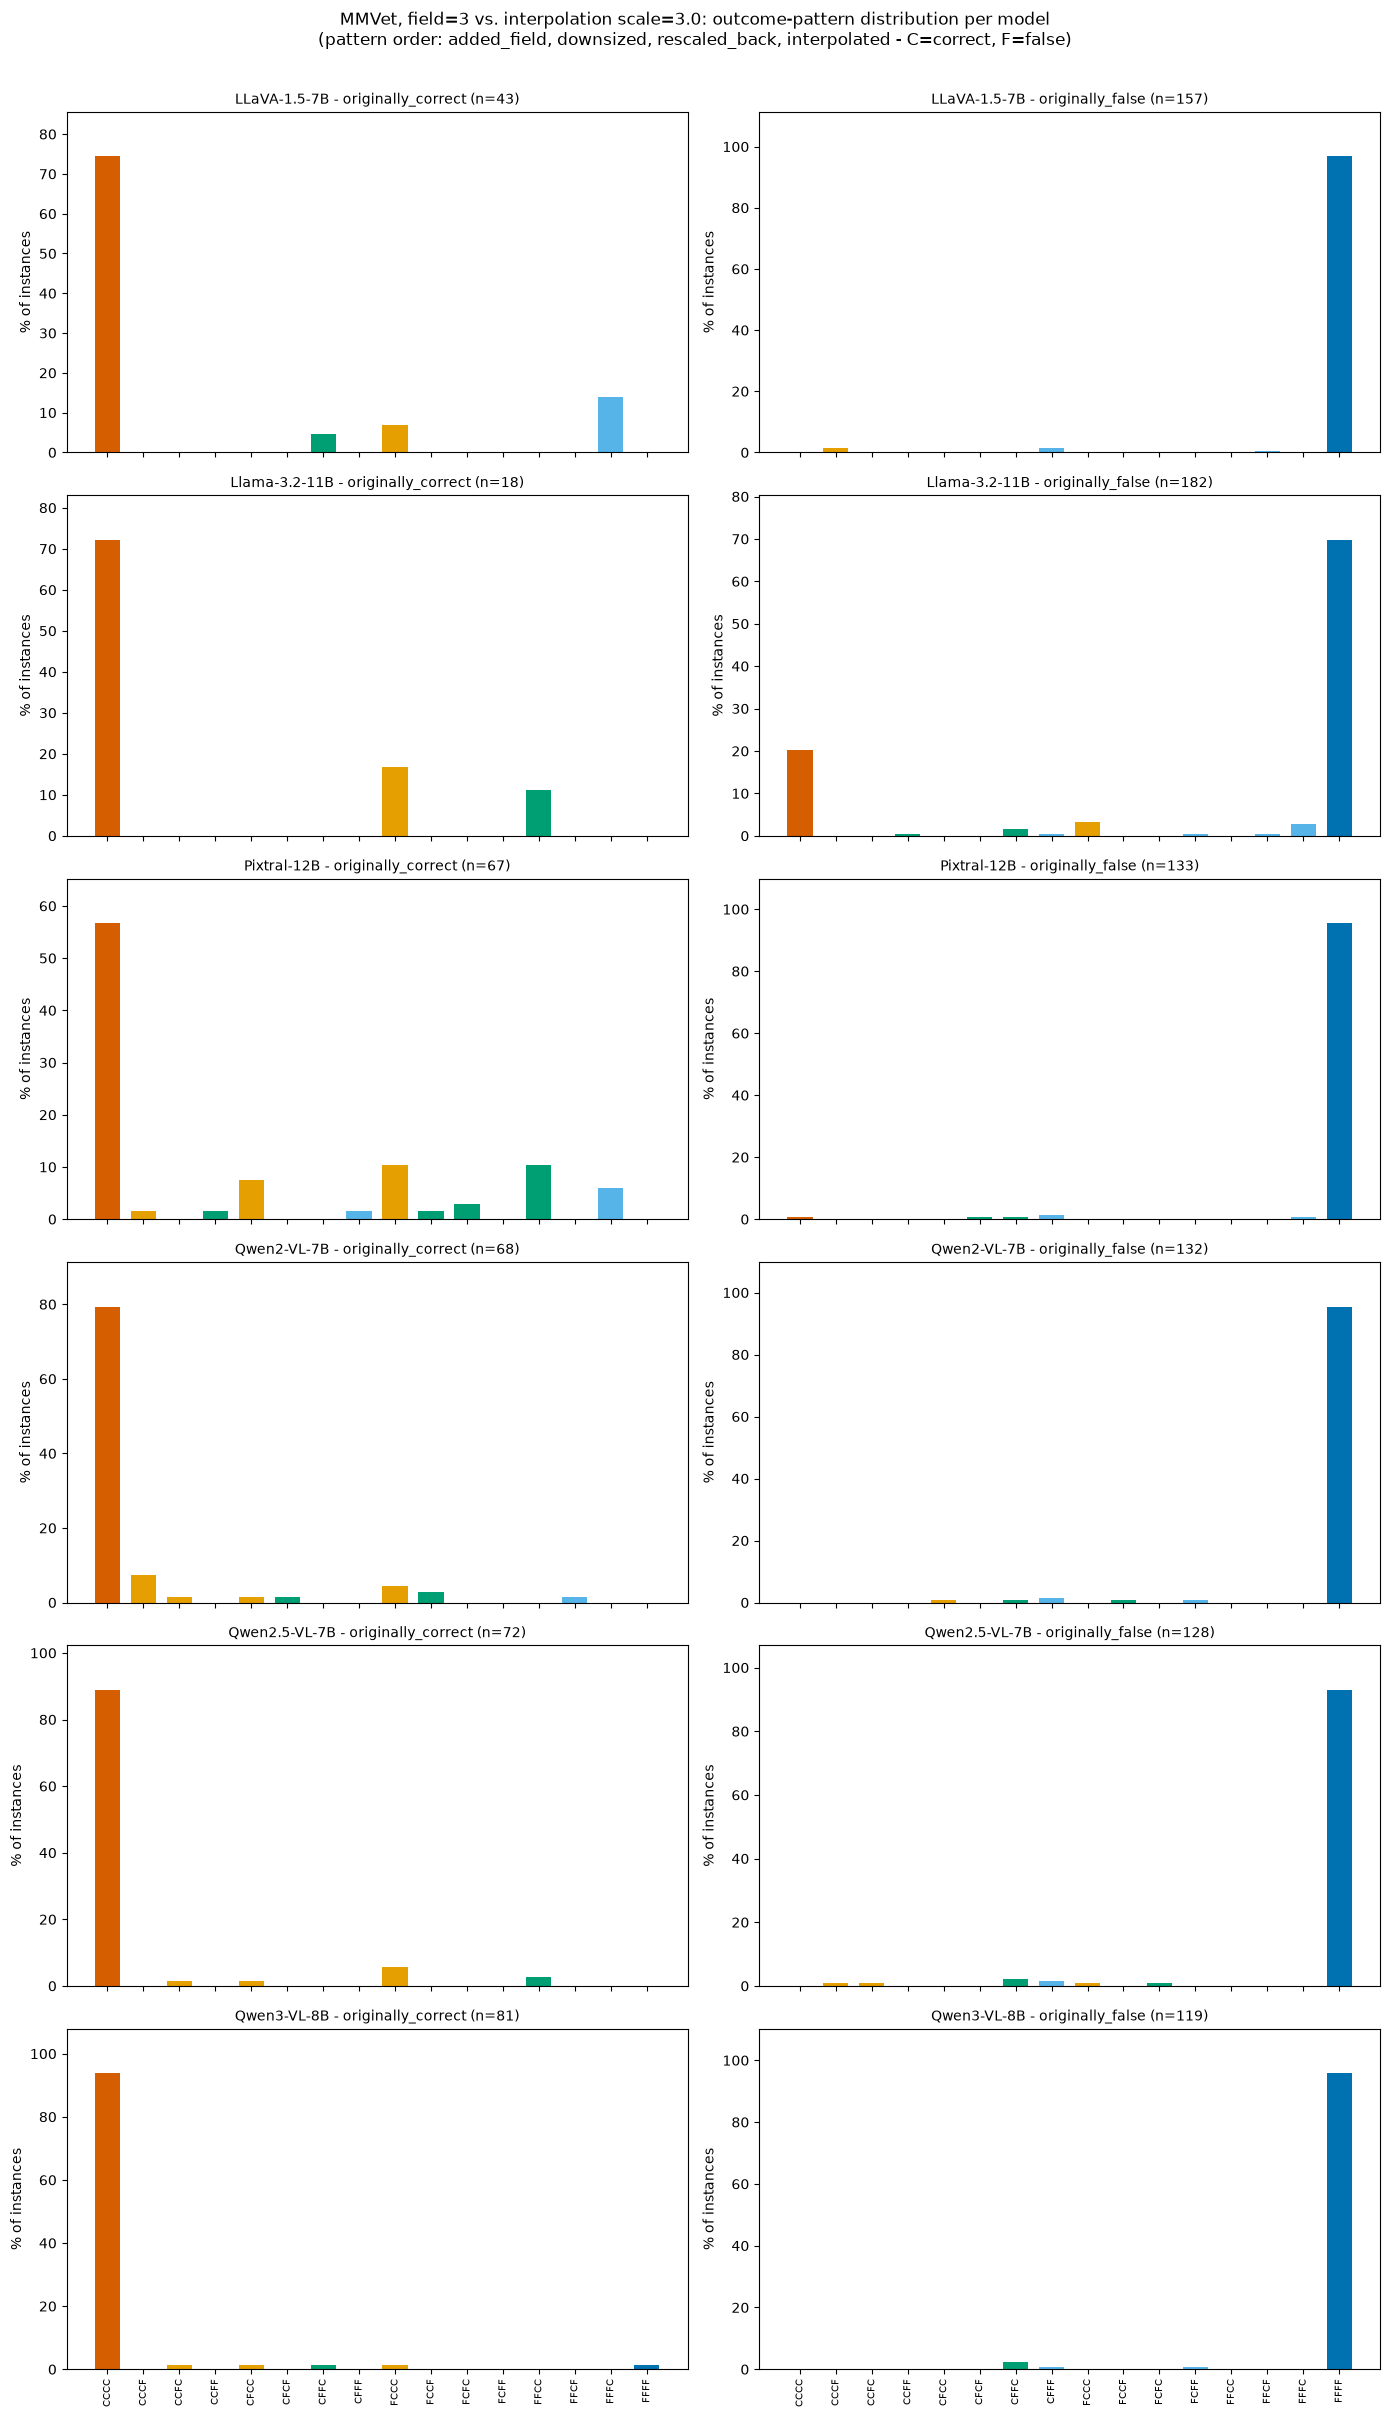

In [20]:
PATTERN_COLOR = {
    0: "#0072B2",  # 0 experiments correct
    1: "#56B4E9",
    2: "#009E73",
    3: "#E69F00",
    4: "#D55E00",  # all 4 experiments correct
}

def bar_colors(patterns):
    return [PATTERN_COLOR[p.count("C")] for p in patterns]


fig, axes = plt.subplots(len(MODELS), 2, figsize=(14, 4 * len(MODELS)), sharex=True)

for row, display in enumerate(MODEL_ORDER):
    for col, group in enumerate(BASELINE_GROUPS):
        ax = axes[row, col]
        pct = summary_table.loc[(display, group)]
        ax.bar(ALL_PATTERNS, pct.values, color=bar_colors(ALL_PATTERNS), width=0.7)
        n = int(group_totals.loc[(display, group)])
        ax.set_title(f"{display} - {group} (n={n})", fontsize=10)
        ax.set_ylabel("% of instances")
        ax.tick_params(axis="x", rotation=90, labelsize=7)
        ax.set_ylim(0, max(pct.values.max() * 1.15, 5))

fig.suptitle(
    "MMVet, field=3 vs. interpolation scale=3.0: outcome-pattern distribution per model\n"
    "(pattern order: added_field, downsized, rescaled_back, interpolated - C=correct, F=false)",
    fontsize=12, y=1.005,
)
fig.tight_layout()
plt.show()

## Aggregate view: how many of the 4 experiments stay correct?

Collapses each 16-way pattern down to "number of the 4 experiments still correct" (0-4), which is
easier to read at a glance than the full 16-pattern breakdown.

In [21]:
instance_df["n_correct"] = instance_df[EXPERIMENTS].eq(1.0).sum(axis=1)

agg = (
    instance_df.groupby(["model", "baseline_group", "n_correct"])
    .size()
    .rename("count")
    .reset_index()
)
agg_pct = agg.pivot_table(index=["model", "baseline_group"], columns="n_correct", values="count", fill_value=0)
agg_pct = agg_pct.div(agg_pct.sum(axis=1), axis=0) * 100
agg_pct.columns = [f"{c}/4 correct" for c in agg_pct.columns]
agg_pct.round(1)

0/4 correct  1/4 correct  2/4 correct  3/4 correct  4/4 correct
model         baseline_group                                                                     
LLaVA-1.5-7B  originally_correct          0.0         14.0          4.7          7.0         74.4
              originally_false           96.8          1.9          0.0          1.3          0.0
Llama-3.2-11B originally_correct          0.0          0.0         11.1         16.7         72.2
              originally_false           69.8          4.4          2.2          3.3         20.3
Pixtral-12B   originally_correct          0.0          7.5         16.4         19.4         56.7
              originally_false           95.5          2.3          1.5          0.0          0.8
Qwen2-VL-7B   originally_correct          0.0          1.5          4.4         14.7         79.4
              originally_false           95.5          2.3          1.5          0.8          0.0
Qwen2.5-VL-7B originally_correct          0.0          0.0          2.8          8.3         88.9
              originally_false           93.0          1.6          3.1          2.3          0.0
Qwen3-VL-8B   originally_correct          1.2          0.0          1.2          3.7         93.8
              originally_false           95.8          1.7          2.5          0.0          0.0